# Calibration maturity by maturity with the exact error, Monte Carlo against Fourier and the interest rate

**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

What this notebook does:

| | What | Where |
|---|---|---|
| 1 | Calibrates Heston maturity by maturity on eight days and shows how the parameters change with maturity | Sections 2 and 3 |
| 2 | Uses the exact error in implied volatility, not the approximation with the vega | Sections 2 and 3 |
| 3 | Finds where the book's conditional Monte Carlo differs from Fourier, and explains why | Section 4 |
| 4 | Documents which interest rate r is used to compute the implied volatilities | Section 5 |

The data are the daily downloads of `..\Data` (8 days, from 7 to 19 October). The notebook does not use the Internet.

**How to run it:** *Run All* in VS Code (about 10 minutes: section 3 is the slow part), or, in a terminal opened in this folder:
`py -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 exact_error_calibration.ipynb`

**Notation:** K = strike, F = forward, k = ln(K/F) (log-moneyness), T = maturity in years, "volatility points" = volatility × 100. Heston parameters: κ (speed of mean reversion), θ (long-run variance), ν (volatility of volatility), ρ (correlation between price and volatility), v0 (today's variance).

## 0. Setup

In [1]:
import os                                     # file paths that work on Windows and Linux
import sys                                    # Python version (reproducibility)
import time                                   # to measure how long each step takes
import numpy as np                            # computation with vectors
import pandas as pd                           # tables
import scipy                                  # only to print its version
import matplotlib                             # only to print its version
import matplotlib.pyplot as plt               # plots
from scipy.optimize import least_squares      # non-linear least squares (as in calibration_by_maturity.ipynb)
import heston_tfg as ht                       # our library (the same file as in the other folders)
from heston_experiment import heston_mc_conditional   # the book's conditional Monte Carlo (heston_experiment.py)

pd.set_option("display.width", 200)           # wide tables
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110})   # plot style

DATA_FOLDER = os.path.join("..", "Data")      # the daily downloads, one subfolder per day
DAYS = ["2026-10-07", "2026-10-09", "2026-10-12", "2026-10-13",
        "2026-10-14", "2026-10-15", "2026-10-16", "2026-10-19"]   # the 8 days used (fixed, so the results do not change)
REF_DAY = "2026-10-12"                        # day of the global calibration (the same as in calibration_by_maturity.ipynb)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5 | matplotlib 3.11.2


## 1. Tools

Four short functions. The first two are the same as in `calibration_by_maturity.ipynb` (sections 1 and 3).

- `load_day`: reads one day of data and computes the implied volatilities (forward by put-call parity, out-of-the-money options, Black-76).
- `iv_bisection`: implied volatility of many strikes at once, by bisection.
- `iv_errors`: the **exact error** in implied volatility of some Heston parameters: σ_model − σ_market for each option. The model volatility is the implied volatility of the Fourier price.
- `calibrate`: finds the parameters that minimise the sum of the squared exact errors, Σ(σ_model − σ_market)², with some parameters fixed if we want, from several starting points.

In [2]:
def load_day(day):
    # Reads the SPX options of one day and returns (r, clean chain with the implied volatilities)
    raw = pd.read_csv(os.path.join(DATA_FOLDER, day, "SPX.csv.gz"))         # one row per option
    market = pd.read_csv(os.path.join(DATA_FOLDER, day, "market.csv"))       # a single row
    spot = float(market["spot_SPX"].iloc[0])                                 # index level at the close
    r = float(market["IRX_13w_tbill_pct"].iloc[0]) / 100                     # 13-week T-bill yield (in %) -> decimal (section 5)
    raw["days"] = (raw["T"] * 365).round().astype(int)                      # days to expiry
    raw = raw[raw["days"] >= 2]                                              # out: options expiring today or tomorrow
    raw["root"] = raw["contractSymbol"].str[:-15]                            # "SPX" (AM) or "SPXW" (PM)
    has_spxw = raw.groupby("expiry")["root"].transform(lambda s: (s == "SPXW").any())
    raw = raw[(raw["root"] == "SPXW") | ~has_spxw]                           # SPXW when the expiry has it
    valid = (raw["bid"] > 0) & (raw["ask"] > raw["bid"])                     # live bid and ask
    n_valid = raw[valid].groupby("days").size()                              # number of valid quotes per expiry
    chosen = []
    for t in ht.TARGET_DAYS:                                                 # 2, 4, 7, ..., 365 days
        near = n_valid[(n_valid.index >= 0.85 * t - 1) & (n_valid.index <= 1.15 * t + 1)]   # expiries within ±15%
        if len(near) == 0:
            near = n_valid.iloc[[np.argmin(np.abs(n_valid.index - t))]]      # if none, the closest one
        chosen.append(int(near.idxmax()))                                    # the most liquid one
    raw = raw[raw["days"].isin(sorted(set(chosen)))]
    chain = ht.build_clean_chain(raw, spot, r=r)                             # forward, OTM options, implied vols, filters
    return r, chain


def iv_bisection(price, F, K, T, r, n_iter=60):
    # Black-76 implied volatility of many strikes at once: the σ is between 0.0001 and 5; we halve the interval 60 times
    low = np.full(len(K), 1e-4)                                              # lower end for each strike
    high = np.full(len(K), 5.0)                                              # upper end
    for _ in range(n_iter):
        mid = 0.5 * (low + high)                                             # midpoint
        too_high = ht.bs_call_fwd(F, K, T, mid, r) > price                   # is the Black-76 price with this σ too high?
        high = np.where(too_high, mid, high)                                 # yes: the right σ is on the left
        low = np.where(too_high, low, mid)                                   # no: it is on the right
    return 0.5 * (low + high)                                                # the centre of the final interval


def iv_errors(p, chain, r):
    # Exact error σ_model − σ_market of every option in `chain` (all its maturities)
    errors = []
    for T, g in chain.groupby("T"):                                          # one maturity at a time
        F, K = g["F"].iloc[0], g["K"].values                                 # forward and strikes
        prices = ht.heston_call_fwd(F, K, T, r, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])   # Heston price (Fourier)
        errors.append(iv_bisection(prices, F, K, T, r) - g["iv"].values)    # implied vol of the model − market
    return np.concatenate(errors)


def calibrate(chain, r, fixed, starts):
    # Minimises Σ(σ_model − σ_market)² over the free parameters; `fixed` = {name: value} that are not touched
    free = [n for n in ht.PARAM_NAMES if n not in fixed]                    # parameters we look for
    pos = [ht.PARAM_NAMES.index(n) for n in free]                           # their position (for the bounds)
    scale = {"kappa": 1.0, "theta": 0.05, "nu": 0.3, "rho": 0.3, "v0": 0.05}   # typical size of each parameter
    full = lambda x: {**fixed, **dict(zip(free, x))}                         # fixed + free -> the 5 parameters
    best = None
    for s in starts:                                                         # several starting points (local minima exist)
        x0 = np.clip([s[n] for n in free], ht.LOWER[pos] + 1e-6, ht.UPPER[pos] - 1e-6)
        sol = least_squares(lambda x: iv_errors(full(x), chain, r), x0,
                            bounds=(ht.LOWER[pos], ht.UPPER[pos]), x_scale=[scale[n] for n in free])
        if best is None or sol.cost < best.cost:                             # we keep the best one
            best = sol
    rmse = 100 * np.sqrt(np.mean(best.fun ** 2))                             # error in volatility points
    return full(best.x), rmse

## 2. Global calibration with the exact error (12 October)

First we calibrate the 5 parameters with **all maturities at once**, now minimising the exact error in implied volatility (in `calibration_by_maturity.ipynb` the global calibration used the approximation (model price − market price)/vega). We keep at most 40 options per maturity, as in `calibration_by_maturity.ipynb`.

In section 3, κ and θ have to be fixed, because a single maturity cannot identify them (`calibration_by_maturity.ipynb`, case A). This calibration tells us whether the exact error gives better values for them.

In [3]:
t0 = time.time()
r_ref, chain_ref = load_day(REF_DAY)                                         # data of 12 October
cal_ref = ht.thin_chain(chain_ref, max_per_T=40)                             # at most 40 options per maturity
v_atm = float(chain_ref.loc[chain_ref["T"].idxmin(), "iv"] ** 2)             # starting v0: ATM variance of the shortest maturity
starts = [dict(kappa=2.0, theta=0.04, nu=0.5, rho=-0.7, v0=v_atm),           # the same 3 starting points as ht.calibrate
          dict(kappa=1.0, theta=0.06, nu=0.3, rho=-0.5, v0=v_atm),
          dict(kappa=5.0, theta=0.04, nu=1.0, rho=-0.8, v0=v_atm)]
glob, rmse_glob = calibrate(cal_ref, r_ref, fixed={}, starts=starts)         # all 5 parameters free
feller = 2 * glob["kappa"] * glob["theta"] / glob["nu"] ** 2                 # Feller ratio (holds if ≥ 1)
print(f"{REF_DAY}: {len(cal_ref)} options, {cal_ref['T'].nunique()} maturities, r = {r_ref:.4f}  ({time.time() - t0:.0f} s)")
print("Exact error:      ", {k: round(float(v), 4) for k, v in glob.items()}, f"| error {rmse_glob:.2f} points | Feller ratio {feller:.3f}")
VEGA_FIT = dict(kappa=9.543, theta=0.0386, nu=1.9396, rho=-0.605, v0=0.0096)   # global calibration of 12 October with the vega approximation (calibration_by_maturity.ipynb)
print("Vega approximation:", VEGA_FIT, "| error 2.08 points | Feller ratio 0.196")

2026-10-12: 520 options, 13 maturities, r = 0.0405  (68 s)
Exact error:       {'kappa': 20.0, 'theta': 0.0358, 'nu': 4.1372, 'rho': -0.521, 'v0': 0.0083} | error 1.37 points | Feller ratio 0.084
Vega approximation: {'kappa': 9.543, 'theta': 0.0386, 'nu': 1.9396, 'rho': -0.605, 'v0': 0.0096} | error 2.08 points | Feller ratio 0.196


**What comes out.** With the exact error the global fit improves (an error of 1.37 volatility points instead of 2.08), but κ ends at its upper bound (20) and ν rises to 4.1. The exact error gives much more weight to the wings of the shortest maturities, where the errors are largest, and the only way Heston has to fit them is a very large ν. κ stuck at the bound means that the data do not pin it down: it is the same identification problem as in `calibration_by_maturity.ipynb`.

For this reason, section 3 keeps the κ and θ of the global calibration with the vega approximation (κ = 9.54, θ = 0.0386), and section 4 uses those parameters. This way the results can also be compared with those of `calibration_by_maturity.ipynb`.

## 3. Heston parameters for each maturity, on the 8 days

For each day and each maturity we calibrate **ν, ρ and v0** with the exact error, with κ and θ fixed at the values of the global calibration with the vega approximation (κ = 9.54, θ = 0.0386; the same for all days, so that the days can be compared). Three starting points per maturity, as in `calibration_by_maturity.ipynb`, because the optimiser can stop at a local minimum.

If Heston with constant parameters were a good model, ν, ρ and v0 would come out the same at all maturities.

In [4]:
fixed = {"kappa": VEGA_FIT["kappa"], "theta": VEGA_FIT["theta"]}                   # κ and θ of the vega-approximation calibration (see section 2)
rows = []
t0 = time.time()
for day in DAYS:                                                             # the 8 days
    r, chain = load_day(day)
    cal = ht.thin_chain(chain, max_per_T=40)                                 # at most 40 options per maturity
    for T, g in cal.groupby("T"):                                            # each maturity separately
        p0 = {"nu": VEGA_FIT["nu"], "rho": VEGA_FIT["rho"], "v0": VEGA_FIT["v0"]}     # start 1: the global values (vega approximation)
        starts_T = [p0, dict(p0, nu=3.0, rho=-0.5), dict(p0, nu=4.5, rho=-0.7)]   # starts 2 and 3: larger ν
        p, rmse = calibrate(g, r, fixed, starts_T)
        rows.append(dict(day=day, days=int(round(T * 365)), nu=p["nu"], rho=p["rho"], v0=p["v0"], error=rmse))
by_maturity = pd.DataFrame(rows)
print(f"{len(by_maturity)} calibrations in {time.time() - t0:.0f} s")

# The same results as tables: one row per maturity (days to expiry), one column per day
by_maturity["horizon"] = [min(ht.TARGET_DAYS, key=lambda t: abs(t - d)) for d in by_maturity["days"]]   # closest target horizon
for name, decimals in [("nu", 2), ("rho", 2), ("v0", 3), ("error", 2)]:
    print(f"\n{name} (rows: target horizon in days; columns: day; NaN = that day has no maturity close to that horizon)")
    display(by_maturity.pivot_table(index="horizon", columns="day", values=name).round(decimals))

102 calibrations in 407 s

nu (rows: target horizon in days; columns: day; NaN = that day has no maturity close to that horizon)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,4.11,3.95,4.51,5.00,4.99,NaN,1.95,5.00
4,2.62,2.77,4.79,NaN,3.88,4.82,2.81,5.00
7,NaN,5.00,2.81,2.69,NaN,5.00,4.00,3.92
10,3.29,3.15,3.07,2.91,3.14,NaN,2.53,4.61
14,2.17,2.69,NaN,2.83,2.91,3.61,4.10,NaN
21,2.35,2.73,2.29,NaN,1.75,1.86,2.05,2.26
30,1.64,1.79,NaN,2.13,1.99,2.11,2.22,NaN
45,1.44,2.00,2.01,2.00,2.03,2.07,2.22,2.29
60,1.85,NaN,2.22,2.22,2.06,2.20,2.28,2.07



rho (rows: target horizon in days; columns: day; NaN = that day has no maturity close to that horizon)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,-0.38,-0.12,-0.31,-0.75,-0.77,NaN,-0.54,-0.71
4,-0.37,-0.51,-0.55,NaN,-0.57,-0.61,-0.62,-0.75
7,NaN,-0.35,-0.45,-0.48,NaN,-0.57,-0.59,-0.72
10,-0.44,-0.12,-0.45,-0.54,-0.62,NaN,-0.63,-0.68
14,-0.50,-0.48,NaN,-0.56,-0.63,-0.59,-0.58,NaN
21,-0.50,-0.48,-0.55,NaN,-0.66,-0.62,-0.64,-0.66
30,-0.53,-0.44,NaN,-0.54,-0.64,-0.59,-0.64,NaN
45,-0.60,-0.59,-0.61,-0.63,-0.67,-0.65,-0.66,-0.68
60,-0.59,NaN,-0.48,-0.49,-0.59,-0.52,-0.62,-0.67



v0 (rows: target horizon in days; columns: day; NaN = that day has no maturity close to that horizon)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,0.011,0.002,0.012,0.014,0.009,NaN,0.006,0.025
4,0.006,0.005,0.011,NaN,0.014,0.008,0.014,0.029
7,NaN,0.008,0.008,0.007,NaN,0.013,0.017,0.022
10,0.009,0.006,0.009,0.010,0.018,NaN,0.015,0.026
14,0.010,0.007,NaN,0.012,0.019,0.017,0.021,NaN
21,0.012,0.010,0.012,NaN,0.019,0.017,0.021,0.026
30,0.013,0.011,NaN,0.015,0.021,0.019,0.023,NaN
45,0.012,0.010,0.011,0.011,0.018,0.015,0.020,0.023
60,0.011,NaN,0.015,0.015,0.020,0.018,0.023,0.024



error (rows: target horizon in days; columns: day; NaN = that day has no maturity close to that horizon)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,1.29,1.30,1.72,2.33,16.34,NaN,0.55,3.11
4,1.35,1.74,1.82,NaN,1.71,7.45,1.08,3.68
7,NaN,1.79,1.68,1.41,NaN,2.23,1.97,1.80
10,1.63,1.65,1.64,1.67,1.66,NaN,1.10,2.18
14,1.19,1.44,NaN,1.51,1.56,1.81,1.95,NaN
21,1.25,1.37,1.09,NaN,0.59,0.71,0.64,0.79
30,0.51,0.76,NaN,0.69,0.66,0.77,0.65,NaN
45,0.26,0.59,0.62,0.65,0.63,0.68,0.48,0.71
60,0.57,NaN,0.20,0.21,0.21,0.26,0.30,0.42


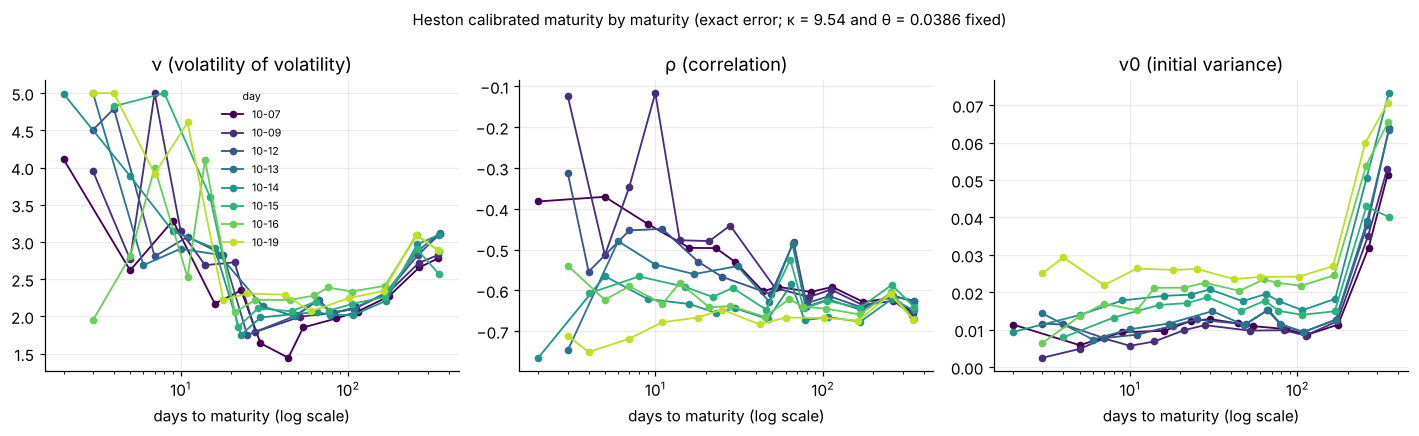

In [5]:
# The plot: ν, ρ and v0 against the maturity, one line per day
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(DAYS)))                    # one colour per day (dark = first day)
for day, c in zip(DAYS, colours):
    d = by_maturity[by_maturity["day"] == day].sort_values("days")
    for ax, name in zip(axes, ["nu", "rho", "v0"]):
        ax.plot(d["days"], d[name], "o-", ms=4, lw=1.2, color=c, label=day[5:])
for ax, title in zip(axes, ["ν (volatility of volatility)", "ρ (correlation)", "v0 (initial variance)"]):
    ax.set_xscale("log"); ax.set_xlabel("days to maturity (log scale)"); ax.set_title(title)
axes[0].legend(fontsize=7, title="day", title_fontsize=7)
fig.suptitle(f"Heston calibrated maturity by maturity (exact error; κ = {VEGA_FIT['kappa']:.2f} and θ = {VEGA_FIT['theta']:.4f} fixed)", fontsize=10)
plt.tight_layout(); plt.savefig("fig_parameters_by_maturity.png", dpi=150); plt.show()

## 4. Where the book's conditional Monte Carlo differs from Fourier, and why

With the parameters of the global calibration of 12 October with the vega approximation (κ = 9.54, θ = 0.0386, ν = 1.94, ρ = −0.605, v0 = 0.0096; Feller ratio 0.20), we price calls at 4 maturities and 6 strikes with two methods: the Fourier formula (exact) and the book's conditional Monte Carlo (`heston_mc_conditional`, 100,000 paths, one step per day, the same seed). We convert both prices into implied volatilities and look at the difference, **Monte Carlo − Fourier, in volatility points**, and at z = (Monte Carlo − Fourier) / standard error: if |z| > 2 the difference is not simulation noise.

To make it simple we use S0 = 100 and r = 0, so the forward is F = 100 and k = ln(K/100).

In [6]:
S0, R0 = 100.0, 0.0                                                           # spot and rate of the experiment (F = S0)
MATURITIES = [7, 30, 90, 180]                                                 # days
K_LOG = [-0.10, -0.05, -0.02, 0.0, 0.02, 0.05]                                # k = ln(K/F)
p = VEGA_FIT                                                                     # parameters of 12 October (vega approximation)
rows = []
t0 = time.time()
for days in MATURITIES:
    T = days / 365
    for k in K_LOG:
        K = S0 * np.exp(k)                                                    # strike
        fourier = float(ht.heston_call_fwd(S0, [K], T, R0, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])[0])
        mc, se = heston_mc_conditional(S0, K, p["v0"], R0, T, p["kappa"], p["theta"], p["nu"], p["rho"],
                                       m=days, n=100_000, seed=1)             # one step per day; same seed everywhere
        iv_f = ht.implied_vol_fwd(fourier, S0, K, T, R0)                       # implied vol of the exact price
        iv_mc = ht.implied_vol_fwd(mc, S0, K, T, R0)                           # implied vol of the Monte Carlo price
        rows.append(dict(days=days, k=k, diff_points=100 * (iv_mc - iv_f), z=(mc - fourier) / se))
mc_zones = pd.DataFrame(rows)
print(f"Time: {time.time() - t0:.0f} s")
print("\nMonte Carlo − Fourier, in volatility points (rows: days; columns: k)")
display(mc_zones.pivot(index="days", columns="k", values="diff_points").round(2))
print("\nz = (Monte Carlo − Fourier) / standard error")
display(mc_zones.pivot(index="days", columns="k", values="z").round(1))

Time: 5 s

Monte Carlo − Fourier, in volatility points (rows: days; columns: k)


k,-0.10,-0.05,-0.02,0.00,0.02,0.05
days,,,,,,
7,1.27,-0.35,-0.05,0.91,0.65,0.34
30,0.34,1.15,1.78,2.41,2.52,1.37
90,2.13,2.66,3.08,3.39,3.61,3.41
180,2.83,3.23,3.51,3.69,3.84,3.95



z = (Monte Carlo − Fourier) / standard error


k,-0.10,-0.05,-0.02,0.00,0.02,0.05
days,,,,,,
7,0.3,-1.0,-0.9,56.8,57.0,18.0
30,1.6,16.1,56.6,139.3,202.5,102.0
90,25.0,60.8,111.8,169.9,244.4,304.8
180,43.3,79.0,116.1,150.6,194.1,272.3


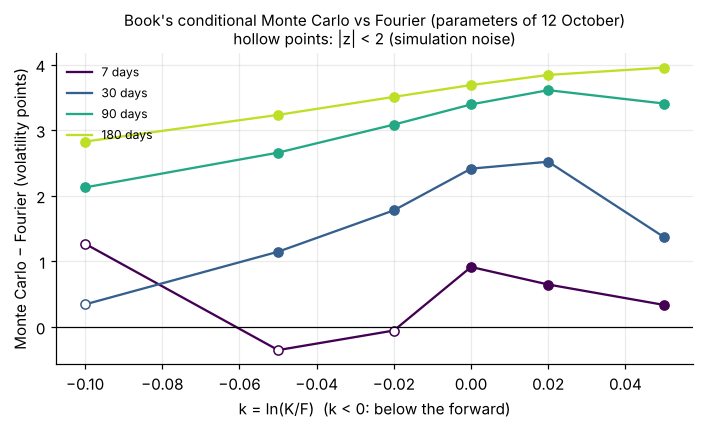

In [7]:
# The plot: difference in volatility points against k, one line per maturity
fig, ax = plt.subplots(figsize=(6.5, 4))
for days, c in zip(MATURITIES, plt.cm.viridis(np.linspace(0, 0.9, len(MATURITIES)))):
    d = mc_zones[mc_zones["days"] == days]
    real = d["z"].abs() >= 2                                                   # the difference is not simulation noise
    ax.plot(d["k"], d["diff_points"], "-", color=c, label=f"{days} days")
    ax.plot(d.loc[real, "k"], d.loc[real, "diff_points"], "o", color=c)                    # filled: real difference
    ax.plot(d.loc[~real, "k"], d.loc[~real, "diff_points"], "o", color=c, mfc="white")     # hollow: |z| < 2, noise
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("k = ln(K/F)  (k < 0: below the forward)"); ax.set_ylabel("Monte Carlo − Fourier (volatility points)")
ax.set_title("Book's conditional Monte Carlo vs Fourier (parameters of 12 October)\nhollow points: |z| < 2 (simulation noise)", fontsize=10)
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig_mc_vs_fourier.png", dpi=150); plt.show()

## 5. Which interest rate r is used to compute the implied volatilities

**What we use.** The yield of the 13-week US Treasury bill (`^IRX` on Yahoo Finance) of the same day, the same for all maturities (4.04–4.09% on these days). It is a risk-free rate in dollars, the currency of the options. It enters in three places: the forward by put-call parity, F = K + e^(rT)(C − P); the discount factor e^(−rT) of the Black-76 formula; and the conversion of puts into calls.

**What is used in practice.** To compute the VIX from the same S&P 500 options, Cboe takes the risk-free rate from the US Treasury yield curve (constant maturity Treasury yields), interpolates it with a cubic spline at each expiry and converts it to a continuously compounded rate. It computes the forward as we do, F = K + e^(RT)(C − P), at the strike where |C − P| is smallest (Cboe, *VIX Mathematics Methodology*).

**Difference with what we do.** Cboe uses one rate for each maturity and we use one short-term rate for all of them. Options are not very sensitive to r (at the money, an error of 0.5 points in r changes the implied volatility of a 3-month option by less than 0.02 points), but the choice must be stated: we use the 13-week Treasury bill; the Treasury curve at each maturity, as Cboe does, would be the more precise choice.

## 6. Conclusions

**1. Heston parameters for each maturity.** Calibrated with the exact error, maturity by maturity, on the 8 days, with κ = 9.54 and θ = 0.0386 fixed:

- **ν is not constant.** It is about 2 between one and six months on all days (1.4–2.4), higher below two weeks (between 2 and 5, and very different from one day to another) and 2.6–3.1 at 9–12 months.
- **ρ** is about −0.6 from one month on (between −0.44 and −0.68), every day; below two weeks it goes from −0.1 to −0.8 depending on the day.
- **v0** is 0.002–0.03 up to six months and 0.03–0.07 at 9–12 months: with κ and θ fixed, it is the parameter that adjusts the level of the long maturities.
- **From one day to another** the shapes are the same from one month on; what moves is the level. v0 at about one month goes from about 0.011 (7–13 October, VIX about 15) to 0.015–0.023 (14–19 October, VIX between 16.5 and 20).
- **Below two weeks Heston does not fit well**: on some days the error is 2–16 volatility points (16 points on 14 October at 2 days) and ν ends at its upper bound of 5. There the parameters are not reliable.

In short: Heston with constant parameters cannot fit all maturities at once, and the parameter that changes most with maturity is ν.

**2. Global calibration with the exact error.** The error falls from 2.08 to 1.37 volatility points, but κ goes to its upper bound (20) and ν to 4.1. The exact error gives a lot of weight to the wings of the shortest maturities, and Heston can only follow them with a very large ν. κ is not identified, and that is why κ and θ are fixed at the values of the vega-approximation calibration.

**3. Where the book's Monte Carlo differs from Fourier, and why.** With the parameters of 12 October:

- Where the difference is real (|z| > 2), the Monte Carlo price is always **too high**.
- The difference **grows with maturity**: at the money, 0.9, 2.4, 3.4 and 3.7 volatility points at 7, 30, 90 and 180 days.
- It is **larger on the right** of the smile (k ≥ 0) than on the left: at 180 days, 2.8 points at k = −0.10 and 4.0 points at k = +0.05. At 7 days and k < 0 there is no real difference.
- **Why:** when the simulated variance becomes negative, the book's scheme takes its absolute value (v → |v|, the reflection). This happens when the variance is close to zero, and it always adds variance, so the prices come out too high. With ρ < 0, the variance falls when the price rises, so the paths where the variance reaches zero are mostly paths where the price has gone up: the extra variance mainly affects the options above the forward (k > 0). The longer the maturity, the more steps reach zero and the more extra variance accumulates. These parameters have a Feller ratio of 0.20, below 1/2, where Milstein with reflection is biased (`feller_monte_carlo.ipynb`).

**4. Interest rate.** We use the 13-week Treasury bill (^IRX) of each day for all maturities. Cboe, for the VIX, uses the Treasury curve interpolated at each maturity. The choice changes the implied volatilities very little (less than 0.02 points for a 3-month at-the-money option per 0.5 points of r), but it has to be stated.

### References

- Cboe. *Cboe Volatility Index (VIX) Mathematics Methodology*. https://cdn.cboe.com/resources/indices/Cboe_Volatility_Index_Mathematics_Methodology.pdf
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *Review of Financial Studies*, 6(2), 327–343.
- Alòs, E. and Merino, R. *Introduction to Financial Derivatives with Python*, 2nd ed., chapter 11. Chapman & Hall/CRC.